# 01 - EDA ulasan Google Play (paylater)

Tujuan: memastikan data mentah layak dipakai sebelum cleaning dan pelabelan.

Yang diperiksa: distribusi bintang, **rentang waktu per bintang**, kualitas teks, campuran bahasa, data pribadi (PII), dan kata-kata yang paling sering muncul.

> **Privasi:** hanya sel "sampel ulasan" di bawah yang menampilkan teks asli. Pakai *Clear All Outputs* sebelum notebook ini di-commit ke GitHub.


In [13]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# cari folder proyek (yang punya src/paths.py) mulai dari lokasi notebook ini
here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(root / "src"))
from paths import FIGURES, RAW

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.dpi"] = 110
print("folder proyek:", root)

folder proyek: C:\Projects\paylater-review-project


## 0. Muat data

In [14]:
files = sorted(RAW.glob("*.csv"))
print([f.name for f in files])

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df["content"] = df["content"].fillna("").astype(str)

print(df.shape)
print("reviewId unik:", df["reviewId"].is_unique)
df.dtypes

['com.finaccel.android.csv', 'id.co.myhomecredit.csv', 'io.silvrr.installment.csv']
(98389, 7)
reviewId unik: True


reviewId                           str
content                            str
score                            int64
thumbsUpCount                    int64
reviewCreatedVersion               str
at                      datetime64[us]
app_id                             str
dtype: object

## 1. Distribusi bintang per aplikasi

Diambil rata per bintang, jadi tabel ini seharusnya hampir seragam. Ini **bukan** distribusi asli di Play Store.


In [15]:
pd.crosstab(df["app_id"], df["score"], margins=True)

score,1,2,3,4,5,All
app_id,,,,,,
com.finaccel.android,4999,691,890,1856,40915,49351
id.co.myhomecredit,6613,754,690,610,7954,16621
io.silvrr.installment,6351,909,721,1015,23421,32417
All,17963,2354,2301,3481,72290,98389


## 2. Rentang waktu per bintang

Sort terbaru + jumlah tetap per bintang berarti bintang yang jarang (biasanya 1-2) bisa membentang jauh lebih lama daripada bintang 5. Kalau rentangnya timpang, model bisa belajar "zaman" ulasan, bukan sentimen.


terlama             terbaru  rentang_hari
app_id                score                                                      
com.finaccel.android  1     2026-03-01 01:20:07 2026-11-16 18:08:55           260
                      2     2026-03-01 08:46:04 2026-11-16 10:55:03           260
                      3     2026-03-01 01:31:48 2026-11-16 17:48:01           260
                      4     2026-03-01 00:27:02 2026-11-16 08:18:14           260
                      5     2026-03-01 00:17:57 2026-11-16 18:38:16           260
id.co.myhomecredit    1     2025-01-01 01:28:05 2026-11-16 17:57:14           684
                      2     2025-01-02 09:20:47 2026-11-16 11:12:29           683
                      3     2025-01-01 00:19:20 2026-11-13 13:31:18           681
                      4     2025-01-01 11:03:14 2026-11-16 09:06:25           683
                      5     2025-01-01 00:02:13 2026-11-16 15:13:08           684
io.silvrr.installment 1     2026-04-01 00:48:54 2026-11-16 17:12:24           229
                      2     2026-04-01 07:18:58 2026-11-16 16:40:53           229
                      3     2026-04-01 12:49:24 2026-11-16 17:19:24           229
                      4     2026-04-01 10:24:20 2026-11-16 14:55:20           229
                      5     2026-04-01 00:26:01 2026-11-16 18:03:49           229

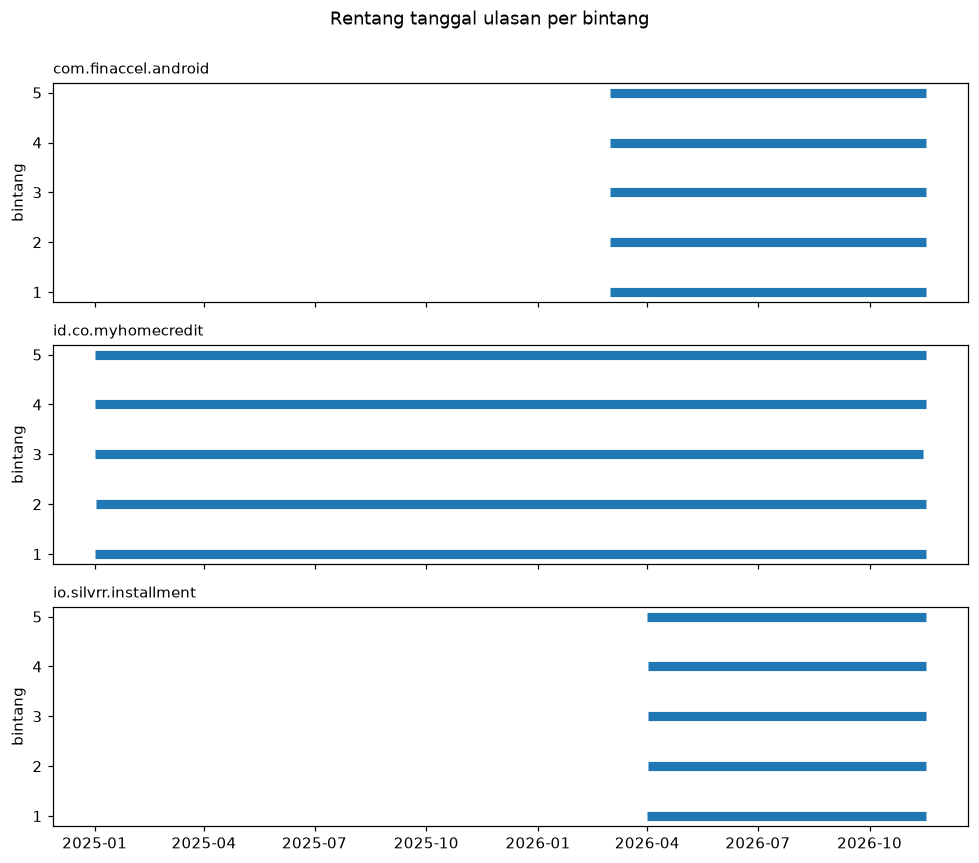

In [16]:
span = (
    df.groupby(["app_id", "score"])["at"]
    .agg(terlama="min", terbaru="max")
    .assign(rentang_hari=lambda t: (t["terbaru"] - t["terlama"]).dt.days)
)
display(span)

apps = sorted(df["app_id"].unique())
fig, axes = plt.subplots(len(apps), 1, figsize=(9, 2.6 * len(apps)), sharex=True, squeeze=False)
for ax, app in zip(axes[:, 0], apps):
    s = span.loc[app]
    ax.hlines(s.index, mdates.date2num(s["terlama"]), mdates.date2num(s["terbaru"]), linewidth=6)
    ax.xaxis_date()
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_ylabel("bintang")
    ax.set_title(app, fontsize=10, loc="left")
fig.suptitle("Rentang tanggal ulasan per bintang", y=1.0)
fig.tight_layout()
fig.savefig(FIGURES / "eda_rentang_waktu.png", bbox_inches="tight")
plt.show()

## 3. Kualitas teks

ulasan kosong: 0
teks sama persis dengan ulasan lain: 42026 (42.7%)
sebaran duplikat per bintang:
score
1     1512
2      120
3      326
4     1408
5    38660

jumlah kata per bintang:


,count,mean,std,min,25%,50%,75%,max
score,,,,,,,,
1,17963.0,17.8,16.7,1.0,6.0,13.0,24.0,102.0
2,2354.0,19.0,16.1,1.0,8.0,14.0,26.0,93.0
3,2301.0,15.5,15.1,1.0,5.0,11.0,21.0,94.0
4,3481.0,8.3,11.2,1.0,1.0,4.0,11.0,103.0
5,72290.0,4.7,7.0,1.0,1.0,2.0,5.0,101.0


share ulasan <= 3 kata per bintang:
score
1    0.154
2    0.093
3    0.195
4    0.488
5    0.623


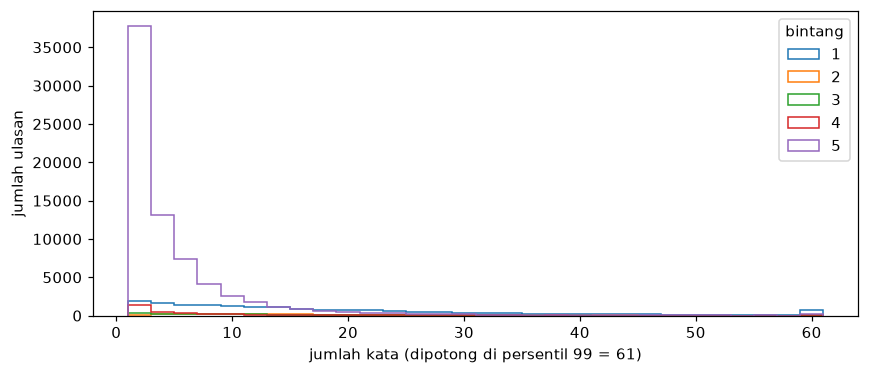

In [17]:
df["n_kata"] = df["content"].str.split().str.len()

kosong = (df["content"].str.strip() == "").sum()
print("ulasan kosong:", kosong)

norm = df["content"].str.lower().str.strip()
dup_mask = norm.duplicated(keep=False) & (norm != "")
print(f"teks sama persis dengan ulasan lain: {dup_mask.sum()} ({dup_mask.mean():.1%})")
print("sebaran duplikat per bintang:")
print(df.loc[dup_mask].groupby("score").size().to_string())

print("\njumlah kata per bintang:")
display(df.groupby("score")["n_kata"].describe().round(1))

print("share ulasan <= 3 kata per bintang:")
print((df["n_kata"] <= 3).groupby(df["score"]).mean().round(3).to_string())

cap = int(df["n_kata"].quantile(0.99))
fig, ax = plt.subplots(figsize=(8, 3.5))
for sc in sorted(df["score"].unique()):
    ax.hist(df.loc[df["score"] == sc, "n_kata"].clip(upper=cap), bins=30, histtype="step", label=f"{sc}")
ax.set_xlabel(f"jumlah kata (dipotong di persentil 99 = {cap})")
ax.set_ylabel("jumlah ulasan")
ax.legend(title="bintang")
fig.tight_layout()
fig.savefig(FIGURES / "eda_panjang_ulasan.png", bbox_inches="tight")
plt.show()

## 4. Bahasa dan noise

Heuristik sederhana berbasis kata umum (bukan detektor bahasa sungguhan). Cukup untuk melihat seberapa banyak ulasan yang jelas bukan bahasa Indonesia.


In [18]:
ID_WORDS = {
    "yang", "dan", "di", "ke", "dari", "untuk", "dengan", "ini", "itu", "tidak", "gak", "ga", "nggak",
    "enggak", "saya", "aku", "kok", "banget", "sudah", "udah", "belum", "bisa", "tapi", "karena", "juga",
    "atau", "kenapa", "tolong", "bagus", "jelek", "mudah", "susah", "ribet", "lama", "mau", "pakai",
    "pake", "sih", "dong", "nih", "jadi", "ada", "cuma", "hanya", "sangat", "sekali", "aplikasi",
    "limit", "tagihan", "bunga", "akun", "tidak", "lagi", "sama", "aja", "saja", "pas", "nya",
}
EN_WORDS = {
    "the", "and", "is", "are", "this", "that", "not", "very", "good", "bad", "to", "of", "for", "with",
    "it", "i", "my", "you", "can", "cannot", "please", "fix", "why", "but", "so", "have", "was", "been",
}


def tebak_bahasa(teks):
    kata = re.findall(r"[a-zA-Z']+", teks.lower())
    n_id = sum(k in ID_WORDS for k in kata)
    n_en = sum(k in EN_WORDS for k in kata)
    if n_id == 0 and n_en == 0:
        return "tidak jelas"
    return "id" if n_id >= n_en else "en"


df["bahasa"] = df["content"].map(tebak_bahasa)
pd.crosstab(df["app_id"], df["bahasa"], normalize="index").round(3)

bahasa,en,id,tidak jelas
app_id,,,
com.finaccel.android,0.033,0.636,0.332
id.co.myhomecredit,0.025,0.765,0.211
io.silvrr.installment,0.026,0.672,0.301


## 5. Data pribadi (PII) di dalam teks

Hanya menghitung, tidak menampilkan isinya. Hasilnya menentukan seberapa penting langkah masking di tahap cleaning.


In [19]:
PII = {
    "telepon": re.compile(r"(?<!\d)(?:\+?62|0)8\d{8,11}(?!\d)"),
    "email": re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+"),
    "angka >= 10 digit (rekening/NIK?)": re.compile(r"(?<!\d)\d{10,}(?!\d)"),
}
pii = pd.DataFrame({nama: df["content"].str.contains(pola) for nama, pola in PII.items()})
display(pii.groupby(df["app_id"]).sum())
print(f"ulasan yang mengandung salah satunya: {pii.any(axis=1).mean():.1%}")

,telepon,email,angka >= 10 digit (rekening/NIK?)
app_id,,,
com.finaccel.android,0,0,0
id.co.myhomecredit,0,0,0
io.silvrr.installment,0,0,0


ulasan yang mengandung salah satunya: 0.0%


## 6. Kata teratas: keluhan (1-2) vs pujian (4-5)

Gambaran awal tentang topik dan kata slang sebelum topic modeling. Daftar stopword di sini sengaja sederhana.


In [20]:
STOP = ID_WORDS | EN_WORDS | {"nya", "yg", "yang", "tau", "apa", "bgt", "udah", "aja", "kalo", "kalau", "gue", "jadi", "banget"}


def kata_teratas(teks, n=15):
    hitung = Counter(
        k for t in teks for k in re.findall(r"[a-z]{3,}", t.lower()) if k not in STOP
    )
    return ", ".join(k for k, _ in hitung.most_common(n))


baris = {}
for app, g in df.groupby("app_id"):
    baris[(app, "bintang 1-2")] = kata_teratas(g.loc[g["score"] <= 2, "content"])
    baris[(app, "bintang 4-5")] = kata_teratas(g.loc[g["score"] >= 4, "content"])
pd.Series(baris, name="kata teratas").to_frame()

kata teratas
com.finaccel.android  bintang 1-2                   bayar, kredivo, telat, padahal, pernah, data, tolak, malah, bulan, pinjaman, hari, tiba, apk, terus, baru
                      bintang 4-5  membantu, kredivo, mantap, cepat, baik, puas, terimakasih, semoga, kasih, terbaik, pinjaman, proses, terima, banyak, keren
id.co.myhomecredit    bintang 1-2                home, data, credit, terus, bayar, hari, padahal, pernah, login, hapus, kredit, malah, apk, pengajuan, jangan
                      bintang 4-5      membantu, home, credit, mantap, cepat, baik, kredit, semoga, kasih, pelayanan, proses, pengajuan, dapat, acc, pinjaman
io.silvrr.installment bintang 1-2           bayar, pinjaman, akulaku, padahal, malah, pernah, pinjam, telat, apk, tolak, terus, tempo, pengajuan, data, jatuh
                      bintang 4-5  membantu, mantap, akulaku, cepat, pinjaman, baik, terimakasih, kasih, bayar, semoga, proses, terima, saat, terbaik, selalu

## 7. Ringkasan angka

Salin keluaran sel ini ke Claude untuk dibahas bersama.


In [21]:
ringkasan = {
    "total ulasan": len(df),
    "jumlah aplikasi": df["app_id"].nunique(),
    "ulasan kosong": int(kosong),
    "teks duplikat (%)": round(dup_mask.mean() * 100, 1),
    "<= 3 kata (%)": round((df["n_kata"] <= 3).mean() * 100, 1),
    "bukan terdeteksi Indonesia (%)": round((df["bahasa"] != "id").mean() * 100, 1),
    "mengandung PII (%)": round(pii.any(axis=1).mean() * 100, 1),
    "rentang hari terpanjang": int(span["rentang_hari"].max()),
    "rentang hari terpendek": int(span["rentang_hari"].min()),
}
pd.Series(ringkasan)

total ulasan                      98389.0
jumlah aplikasi                       3.0
ulasan kosong                         0.0
teks duplikat (%)                    42.7
<= 3 kata (%)                        51.0
bukan terdeteksi Indonesia (%)       33.0
mengandung PII (%)                    0.0
rentang hari terpanjang             684.0
rentang hari terpendek              229.0
dtype: float64

In [22]:
tj = df[df["bahasa"] == "tidak jelas"]
print("share <=3 kata di 'tidak jelas':", round((tj["n_kata"] <= 3).mean(), 3))
tj.sample(15, random_state=0)[["score", "content"]]

share <=3 kata di 'tidak jelas': 0.904


,score,content
52637,4,nice
26986,5,terimakasihh
96003,5,mantap
44933,5,mantap
43078,5,kredivo memang sip ajip...
7414,1,apk pinjol terbaik
63381,5,ok
82557,5,terbaikkk
80021,5,makasih ya
65950,5,Manatp


## 8. Sampel ulasan 


In [23]:
df.sample(10, random_state=0)[["app_id", "score", "content"]]

,app_id,score,content
64597,id.co.myhomecredit,5,mntap
53911,id.co.myhomecredit,5,baik
24964,com.finaccel.android,5,mantap pinjaman mudah dan amanah terimakasih 🙏
10765,com.finaccel.android,5,ini benar sangat membantu saya
35346,com.finaccel.android,5,sangat membantu
50225,id.co.myhomecredit,1,orang disruh daftar. sudah ngisi data tau taunya pengajuan di tolak. hati² data² saya jangan di salah gunakan trimakasih
16535,com.finaccel.android,5,baru pertama tp sangat mudah
55424,id.co.myhomecredit,1,"saya pengguna hci dari dulu,tahun lalu saya Ambil pembiyaan tuna sebesar 18.900.000 di aplikasi setelah pencairan di potong biaya administrssi yg cukup mencekik,rentenir2 seperti kalian kok masih ..."
66953,io.silvrr.installment,1,gak bisa Qris
82427,io.silvrr.installment,5,akulaku sangat membantu banget saat kondisi mendesak ya meskipun kmarin ada keterlambatan saya untuk pembayaran dan ada bunga yg berjalan tapi its omey masih bisa tertoleran sii admin nya jua baik...
